# 00 · Email Parsing

**Goal:** turn time entries sent by email into the same fields as every other entry (CMID, client, matter, hours, narrative) before matching starts.

Typed sheets, PDFs, and handwritten sheets have their own CMID, client, and matter fields. Emails don't: everything is in the body, mixed with greetings, sign-offs, and phone footers. A firm would pull those fields out as part of extraction, so the matching notebooks should see emails the same way.

**Output:** `results/00_entries.parquet`, every entry with the email rows parsed. Notebook 02 reads it instead of the raw entries.

**Approach:** rules only, no model and nothing learned from labeled entries. The rules come from general email and billing conventions, and the firm's own client list:

| Step | What it handles | Example |
|---|---|---|
| Strip clutter | reply chains, quoted lines, signatures, phone footers, confidentiality notices, greetings | "On Oct 14 ... wrote:", "Sent from my iPhone", "Thanks,\nAlex" |
| Strip requests | notes to the person entering time | "Please enter the following for today:" |
| Hours | decimals, minutes, hours and minutes, clock style | ".4", "1.5 hrs", "45 min", "1 hr 15 min", "1:15" |
| CMID | client-matter numbers with any separator | "7215.003", "7215-003", "C/M 7215/003" |
| Client | names, aliases, and initials from the firm's client list, allowing typos and missing spaces | "HalvorsenIndustrial", "JPC", "NCP" |
| Matter | "Client / Matter" pairs, labeled fields, and codename headers | "Cobalt Ridge Partners / Fund II", "Matter: Series C" |
| Fallback | a short name-like header at the start, for clients not on the list yet | "Quarry Lane Ventures - kickoff call" |

**Questions**
1. What do email entries look like next to the other formats?
2. Does the parser handle common email formats it wasn't built around?
3. How often does it recover the right hours, client, and CMID?
4. What does it miss?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from clean import clean_cmid, is_blank
from fuzzy import client_name_table, matter_name_table, match
from email_parser import parse_email, parse_email_entries, client_lookup, matter_lookup

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
EXAMPLES_PATH = Path("../data/email_examples.json")
SHORTHAND_PATH = Path("../data/shorthand_bank.csv")   # billing shorthand, never read as client initials
RESULTS_DIR = Path("../results")

ENTRY_COLS = {"Time ID": "entry_id", "TK ID": "tk_id", "Source Format": "source_format", "Date": "work_date",
              "CMID": "cmid", "Client": "client", "Matter": "matter", "Narrative": "narrative", "Hours": "hours"}
SKIP_CLIENTS = ["Firm"]   # an ordinary word, so "firm meeting" doesn't name a client
CLIENT_MIN = 80           # typed client score that counts as pointing to a client (same scale as notebook 01)

## 2. Load data

The answer key (`KEY:` columns) is only used to check the parser at the end. The parser itself only sees the entry and the firm's client and matter lists.

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype=str)
raw, matter_master = sheets["Time Entries"], sheets["Matter Master"]

entries = raw[list(ENTRY_COLS)].rename(columns=ENTRY_COLS)
answers = raw[["Time ID", "KEY: Split", "KEY: True CMID", "KEY: True Client", "KEY: Entry Category"]]
answers.columns = ["entry_id", "split", "true_cmid", "true_client", "category"]
acronym_skip = pd.read_csv(SHORTHAND_PATH)["shorthand"].tolist()
client_names = client_name_table(matter_master, acronym_skip)
matter_names = matter_name_table(matter_master)

assert entries["entry_id"].is_unique
assert not any(c.startswith("KEY") for c in entries.columns)
print(f"{len(entries):,} entries | {(entries['source_format'] == 'EMAIL').sum()} emails | {len(client_names)} client names, aliases, and initials")

4,000 entries | 389 emails | 83 client names, aliases, and initials


## 3. What emails look like

In [4]:
filled = entries[["cmid", "client", "matter"]].notna().groupby(entries["source_format"]).mean()
filled.round(2)

,cmid,client,matter
source_format,,,
EMAIL,0.00,0.00,0.00
HANDWRITTEN,0.54,0.74,0.31
PDF,0.53,0.75,0.33
TYPED,0.55,0.75,0.31


In [5]:
emails = entries[entries["source_format"] == "EMAIL"]
emails["narrative"].sample(8, random_state=0).to_frame()

,narrative
633,0:24 Halverson Industries-gen exchange emails ...
1301,1.2 CRP prepare first dft of drawdown notice r...
2792,[MeridianTherapeutics] Make edits to governanc...
1753,0.6 Maridian Therapeutics Follow up with clien...
2980,Lantern Software Group: Revw funds flow for Vi...
2318,.3 Lnaternfish Software / Exec Comp / 409AA Fo...
3208,1.1 Lumen Oak Health Attend closing call. -SK
2975,Solaca Health: provide cmts on foreign qualifi...


- **Emails come in with no CMID, client, or matter at all,** while the other formats have each field about a third to three quarters of the time.
- The client, matter, and hours are usually in the body, along with requests ("Pls enter"), sign-offs ("thx, LM"), and phone footers.
- Without parsing, the matching model treats every email like an entry where nobody filled anything in, even when the client is written right there.

## 4. Check on common email formats

Before running on the synthetic emails, the parser is checked on emails written to look like ones a legal assistant actually gets: Outlook replies with the old thread below, phone replies, a list of several entries, a labeled form, a confidentiality notice, a forward, and minutes or clock-style hours. None of these layouts are in the synthetic data. They use the synthetic firm's clients, since the parser looks names up in the firm's own list. The emails and what a person would pull out of each one are in `data/email_examples.json`.

In [6]:
examples = json.loads(EXAMPLES_PATH.read_text())
print(examples[0]["text"])

Hi Pat,

Please enter the following for today:
Harborlight Bio / General Corporate - reviewed board consent for option grants, 0.6 hrs

Thanks,
Alex

Alex Chen | Associate
Corporate Group

From: Pat Lee
Sent: Monday, October 12, 2026 9:02 AM
To: Alex Chen
Subject: Time for last week?

Hi Alex, can you send me your time from last week?


In [7]:
lookup = client_lookup(client_names, SKIP_CLIENTS)
matters = matter_lookup(matter_names)

rows = []
for ex in examples:
    found = parse_email(ex["text"], lookup, matters)
    got = [{"client": f["client"], "hours": f["hours"], "cmid": f["cmid"]} for f in found]
    for f in found:
        rows.append({"layout": ex["layout"], **f, "as_expected": got == ex["expected"]})
general = pd.DataFrame(rows)
print(f"{general.drop_duplicates('layout')['as_expected'].sum()} of {len(examples)} emails parsed as expected")
general

10 of 10 emails parsed as expected


,layout,cmid,client,matter,hours,narrative,as_expected
0,Outlook reply,NaN,Harborlight Bio,General Corporate,0.60,reviewed board consent for option grants,True
1,Phone reply,NaN,Meridian Therapeutics,NaN,1.50,annual meeting - revised proxy draft and sent ...,True
2,List of entries,9140.001,Juniper Peak Capital,NaN,0.40,call with GP re LPA comments,True
3,List of entries,NaN,Cobalt Ridge Partners,Fund II,1.20,revise subscription docs,True
4,List of entries,NaN,Pelican Row Holdings,NaN,1.00,review title commitment,True
5,Labeled fields,NaN,Lanternfish Software,Series C Financing,2.25,Drafted disclosure schedules and circulated to...,True
6,Confidentiality notice,NaN,Pelican Row Holdings,NaN,0.75,call w/ title co re survey exceptions,True
7,Minutes and CMID,7215.003,NaN,NaN,0.50,reviewing the Asterion amendment redline.,True
8,Client not on the list,NaN,Quarry Lane Ventures,NaN,0.80,kickoff call re new engagement,True
9,Alias and clock hours,NaN,JPC,NaN,1.25,fund II - markup of side letter,True


- **All 10 formats come out as expected,** including the ones with reply chains, signatures, and a confidentiality notice below the entry.
- A list of entries becomes one entry per line, each with its own client and hours.
- "Rule 10b5-1" and "Item 5.02" aren't read as hours, since billing hours come in tenths and a word like "Rule" or "Item" right before a number marks it as a reference.
- A client that isn't on the list ("Quarry Lane Ventures") still lands in the client field, so matching can see a client name that doesn't match anything, which is a hint for `NO_MATCH`.

## 5. Run on the synthetic emails

In [8]:
parsed = parse_email_entries(entries, client_names, matter_names, skip=SKIP_CLIENTS)
is_email = parsed["source_format"] == "EMAIL"

assert parsed.index.equals(entries.index)
assert parsed.loc[~is_email, ["cmid", "client", "matter", "narrative"]].equals(entries.loc[~is_email, ["cmid", "client", "matter", "narrative"]])
print("Entries found per email:", parsed.loc[is_email, "n_parsed"].value_counts().to_dict())

before_after = entries.loc[is_email, ["narrative"]].join(parsed.loc[is_email, ["cmid", "client", "matter", "parsed_hours", "narrative"]], rsuffix="_parsed")
before_after.sample(8, random_state=1)

Entries found per email: {1: 389}


,narrative,cmid,client,matter,parsed_hours,narrative_parsed
1025,1.8h Pelican Row Holdings Attend to drafting o...,NaN,Pelican Row Holdings,NaN,1.8,Attend to drafting of zoning letter
1802,[Cobalt] update capital account statements -- ...,NaN,Cobalt,NaN,2.8,update capital account statements
1315,[Harborlight Bio / gen corp] Handle annual fil...,NaN,Harborlight Bio,gen corp,0.3,Handle annual filings and follow up on open it...
677,Firm / firm admin: Complete conflicts training...,NaN,Firm,firm admin,0.7,Complete conflicts training.
2450,[Ridgewater] attend to LP matters. -- 2.0 hrs -EB,NaN,Ridgewater,NaN,2.0,attend to LP matters.
3510,Pls enter 2.2 for Meridian Tx - Exchange email...,NaN,Meridian Tx,NaN,2.2,Exchange emails with R. Iyer re say-on-pay; lo...
2617,Pls enter 1:18 for Meridian Tx - Read through ...,NaN,Meridian Tx,NaN,1.3,Read through governance guidelines.
3216,Ridgawater Partners / Fund IV: attend to fund ...,NaN,Ridgawater Partners,Fund IV,0.9,attend to fund formatiion matters


## 6. How well it parses

Each TRAIN and VAL email is checked against the answer key (TEST is left for the final run):
- **Hours:** the parsed hours vs. the `Hours` column
- **Client:** does the parsed client point to the true client (same fuzzy matching as notebook 01, score 80+)? Or does it point to the *wrong* client, which is worse than leaving the field blank?
- **CMID:** when one is found, is it the true CMID after cleanup?
- **New clients:** for emails from a client that isn't in Matter Master, does the client field get filled?

In [9]:
def pointed_client(name):
    top = match(name, client_names, k=1) if not is_blank(name) else []
    return top[0][0] if top and top[0][1] >= CLIENT_MIN else None


check = parsed[is_email].merge(answers.query("split != 'TEST'"), on="entry_id")
check["client_pick"] = check["client"].map(pointed_client)
check["known"] = check["true_cmid"] != "NONE"
check["hours_diff"] = (check["parsed_hours"].astype(float) - check["hours"].astype(float)).abs()

check["hours_match"] = check["hours_diff"] < 0.05
check["hours_close"] = check["hours_diff"] <= 0.15
check["client_filled"] = check["client"].notna()
check["right_client"] = check["client_pick"] == check["true_client"]
check["wrong_client"] = check["client_pick"].notna() & ~check["right_client"]
check["matter_filled"] = check["matter"].notna()

known = check[check["known"]].groupby("split")[["right_client", "wrong_client"]].mean()
new = check[~check["known"]].groupby("split")["client_filled"].mean().rename("new_client_filled")
scores = check.groupby("split")[["hours_match", "hours_close", "client_filled", "matter_filled"]].mean().join(known).join(new)
scores.insert(0, "emails", check.groupby("split").size())
scores = scores.reindex(["TRAIN", "VAL"])
scores.round(3)

,emails,hours_match,hours_close,client_filled,matter_filled,right_client,wrong_client,new_client_filled
split,,,,,,,,
TRAIN,273,0.96,1.0,0.769,0.308,0.735,0.016,0.750
VAL,67,0.94,1.0,0.701,0.224,0.655,0.052,0.444


In [10]:
found = check[check["cmid"].notna()]
print(f"CMIDs found: {len(found)} | right after cleanup: {(found['cmid'].map(clean_cmid) == found['true_cmid']).sum()}")

CMIDs found: 19 | right after cleanup: 6


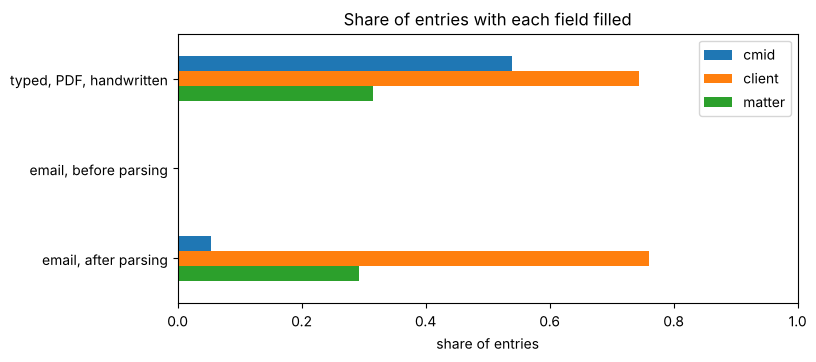

In [11]:
fill = pd.DataFrame({
    "typed, PDF, handwritten": entries.loc[~is_email, ["cmid", "client", "matter"]].notna().mean(),
    "email, before parsing": entries.loc[is_email, ["cmid", "client", "matter"]].notna().mean(),
    "email, after parsing": parsed.loc[is_email, ["cmid", "client", "matter"]].notna().mean(),
})
ax = fill.T.plot.barh(figsize=(8, 3.5), xlim=(0, 1), title="Share of entries with each field filled")
ax.set_xlabel("share of entries")
ax.invert_yaxis()
plt.show()

- **Hours match the written amount every time.** About 96% match the `Hours` column exactly, and the rest are all within 0.15 hours: the email says ".8" and the column has 0.75, or the email says "1.6" for a 1.5 entry. That's the synthetic data's rounding, not a parsing miss.
- **The client field goes from always empty to filled for about three quarters of emails,** a bit more than typed entries. It points to the right client for about 70% of emails from known clients (74% on TRAIN, 66% on VAL) and to a wrong one for 2 to 5%.
- **The results are similar on TRAIN and VAL,** as expected for rules that aren't fit to any split. VAL only has about 70 emails, so a few entries move its numbers by several points.
- **CMIDs are rare in emails** (about 1 in 20), and only about a third of the ones written are real CMIDs. The rest are typos like "Zg60.003" or numbers that aren't in Matter Master, which matching already treats as a mismatch clue.
- **Most new-client emails get a client name** (fewer on VAL), which gives matching a name that doesn't fit any client.

## 7. What it misses

In [12]:
missed = check[check["known"] & (check["client_pick"] != check["true_client"])]
missed["category"].value_counts().rename("emails without the right client").to_frame()

,emails without the right client
category,
MESSY,28
INCOMPLETE,26
AMBIGUOUS,22
SPLIT_NAMED,6
SPLIT_UNNAMED,4


In [13]:
missed.merge(raw[["Time ID", "Narrative"]], left_on="entry_id", right_on="Time ID")[["Narrative", "client", "true_client"]].head(12)

,Narrative,client,true_client
0,"time for today: HB, Edit good standing certifi...",NaN,Harborlight Bio
1,Pls enter 2:36: mark up inv. register; circula...,NaN,Cobalt Ridge Partners
2,"time for today: 5524-002, exchange emails w/ W...",NaN,Cobalt Ridge Partners
3,Attend to annual filings; plus time on other d...,NaN,Bluefin Robotics
4,Attend practice group mtg (0.4),NaN,Firm
5,time for today: Cobalt Rock Partners / fund ge...,Cobalt Rock,Cobalt Ridge Partners
6,Pls enter 0.4: Attend to property acquisition.,NaN,Pelican Row Holdings
7,[Project Atlas] attend to rvw of escrow agt in...,NaN,Northgate Capital Partners
8,"Pls enter 0.4h: T/c w/ M. Carter. thx, FC",NaN,Pelican Row Holdings
9,42 min Firm interview summer associate candidates,NaN,Firm


- **Most misses (about 8 in 10) have no client in the email at all** ("Pls enter 0.4: Attend to property acquisition."). There's nothing to parse, and matching has to rely on the narrative and the timekeeper's history, the same as an incomplete typed entry.
- **Short or shared initials** ("HB", "PL") aren't recognized. Initials are only built from the client list when they're three or more letters and belong to one client ("CRP"), and the rest need the firm's alias list, which grows as reviewers confirm matches.
- **Lookalike names** like "Cobalt Rock Partners" get read as the closest real client name ("Cobalt Rock", an alias of Cobalt Rock Capital). That's the right reading of what was written, and matching decides between the two.
- **Truncated names** ("Aster &", "Pelican Row Ho") fall below the match score and stay in the narrative.

## 8. Save

`00_entries.parquet`: every entry in the same order as the raw file, with email rows parsed into `cmid`, `client`, `matter`, and `narrative`. `parsed_hours` and `n_parsed` are kept for reference. Other formats are unchanged.

In [14]:
out = parsed.drop(columns=["hours"])
out.to_parquet(RESULTS_DIR / "00_entries.parquet", index=False)
print(f"Saved 00_entries.parquet: {len(out):,} entries, {is_email.sum()} parsed emails")

Saved 00_entries.parquet: 4,000 entries, 389 parsed emails


## 9. Findings

- **Emails were the one format where matching saw nothing in the client, matter, or CMID fields,** even though most emails name the client. That made emails look harder to the model than they are.
- **A rule-based parser recovers the fields for most emails:** the client field is filled for about three quarters of them, hours match what was written, and wrong clients are rare (2 to 5%).
- **It works on email layouts it wasn't built around** (reply chains, forwards, signatures, notices, lists of entries, labeled forms).
- **The parser only uses what a firm has:** the email itself and the client and matter lists. No answer key, no learned weights.

## Limitations

- The synthetic emails come from a generator with a fixed set of phrasings, so the scores in section 6 are likely higher than on real emails. The general emails in section 4 are a better sense of how it handles new layouts, but they're still made up.
- The client list is the main source of client names. Nicknames, and initials that are short or shared by two clients, only work once they're on the alias list.
- An email with several entries keeps the first entry's fields and joins the narratives, like a block-billed entry. In the app, each entry would be its own row.
- Only plain text is handled. HTML emails would need to be converted to text first (most email exports already do this).

## Next steps

- `01_fuzzy_scorer_comparison`: pick the fuzzy scorers for typed client and matter names.
- `02_feature_building`: build the matching clues from `00_entries.parquet`, so emails go through matching with their fields filled in.
